Saving pic1dirty.jpg to pic1dirty (1).jpg


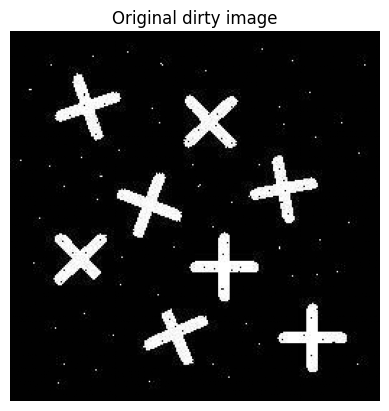

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
img = cv2.imread("pic1dirty.jpg", cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.title("Original dirty image")
plt.axis("off");

[  0 255]


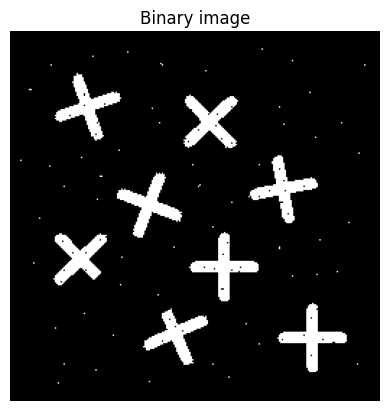

In [8]:
_, binary = cv2.threshold(
    img, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
plt.imshow(binary, cmap='gray')
print(np.unique(binary))
plt.title("Binary image")
plt.axis("off");

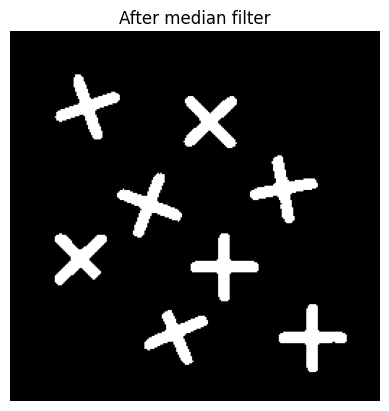

In [9]:
median = cv2.medianBlur(img, 3)

_, binary_clean = cv2.threshold(
    median, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
plt.imshow(binary_clean, cmap='gray')
plt.title("After median filter")
plt.axis("off");

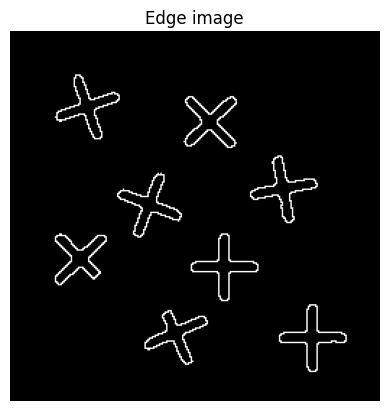

In [16]:
kernel = np.ones((3,3), np.uint8)
eroded = cv2.erode(binary_clean, kernel, iterations=1)
edges = binary_clean - eroded
plt.imshow(edges, cmap='gray')
plt.title("Edge image")
plt.axis("off");

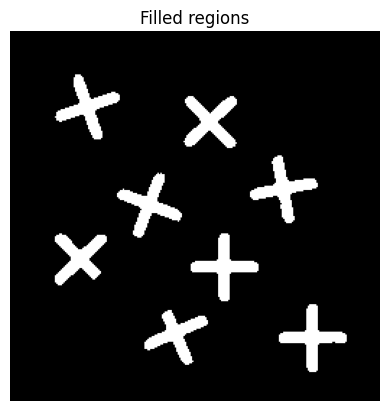

In [17]:
filled = edges.copy()
h, w = filled.shape
mask = np.zeros((h + 2, w + 2), np.uint8)
cv2.floodFill(filled, mask, (0, 0), 255)
filled_inv = cv2.bitwise_not(filled)
filled_regions_img = edges | filled_inv
plt.imshow(filled_regions_img, cmap='gray')
plt.title("Filled regions")
plt.axis("off");


Number of objects: 8


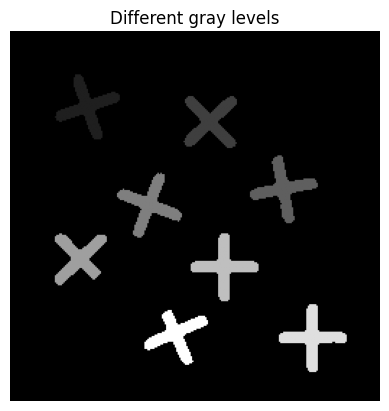

In [18]:
num_labels, labels = cv2.connectedComponents(filled_regions_img, connectivity=8)
print("Number of objects:", num_labels - 1)
labels_gray = np.zeros_like(filled_regions_img, dtype=np.uint8)
if labels.max() > 0:
    labels_gray = np.uint8(255 * labels / labels.max())
plt.imshow(labels_gray, cmap='gray')
plt.title("Different gray levels")
plt.axis("off");